In [ ]:
from google.colab import drive
import os
import shutil

# 1. Google Drive'ı Bağla
drive.mount('/content/drive')

# 2. Drive'dan yedeklenen dosyaları yerel disk alanına kopyala
print("Yedek dosyaları Google Drive'dan indiriliyor...")
shutil.copy('/content/drive/My Drive/opencv_cuda/cv2_cuda_backup.zip', '/content/')
shutil.copy('/content/drive/My Drive/opencv_cuda/opencv_libs_backup.zip', '/content/')

# 3. Python paket klasörünü oluştur ve dosyaları çıkart
print("Python cv2 paketi kuruluyor...")
os.makedirs('/usr/local/lib/python3.13/dist-packages/cv2', exist_ok=True)
!unzip -q -o /content/cv2_cuda_backup.zip -d /usr/local/lib/python3.13/dist-packages/cv2

# 4. Paylaşılan C++ kütüphanelerini çıkart
print("Sistem paylaşımlı kütüphaneleri (.so) geri yükleniyor...")
!unzip -q -o /content/opencv_libs_backup.zip -d /usr/local/lib

# 5. Sistem dinamik kütüphane bağlayıcısını güncelle
print("Kütüphane yolları sistemde güncelleniyor...")
!ldconfig

# 6. Test Et
print("\n=== KURULUM TAMAMLANDI ===")
import cv2
cuda_devices = cv2.cuda.getCudaEnabledDeviceCount()
print(f"CUDA Destekli Cihaz Sayısı: {cuda_devices}")
if cuda_devices > 0:
    print("Tebrikler! OpenCV CUDA desteğiyle başarıyla geri yüklendi.")
    cv2.cuda.printCudaDeviceInfo(0)
else:
    print("Uyarı: Kurulum tamamlandı ancak GPU etkinleştirilmemiş olabilir. Runtime ayarlarından GPU seçtiğinize emin olun.")

Mounted at /content/drive
Yedek dosyaları Google Drive'dan indiriliyor...
Python cv2 paketi kuruluyor...
Sistem paylaşımlı kütüphaneleri (.so) geri yükleniyor...
Kütüphane yolları sistemde güncelleniyor...
/sbin/ldconfig.real: /usr/local/lib/libtbbbind_2_5.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libumf.so.1 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbb.so.12 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbbind.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_adapter_level_zero.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_adapter_level_zero_v2.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbmalloc_proxy.so.2 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libhwloc.so.15 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_adapter_opencl.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libjulia.so.1.12 is not a sym

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def custom_block_matching(img_left, img_right, block_size=15, max_disparity=64):
    """
    Sıfırdan blok eşleştirme (Block Matching) algoritması (SAD yöntemi ile).
    """
    height, width = img_left.shape
    disparity_map = np.zeros((height, width), dtype=np.float32)
    half_block = block_size // 2

    # Sınır dışına taşmayı önlemek için pencereleri kaydırarak tarıyoruz
    for y in range(half_block, height - half_block):
        for x in range(half_block, width - half_block):

            # Sol görüntüdeki referans bloğu (template)
            block_left = img_left[y - half_block : y + half_block + 1,
                                  x - half_block : x + half_block + 1]

            best_sad = float('inf')
            best_disp = 0

            # Sağ görüntüde sol satır boyunca sola doğru arama yapıyoruz
            for d in range(0, min(max_disparity, x - half_block)):
                block_right = img_right[y - half_block : y + half_block + 1,
                                        x - d - half_block : x - d + half_block + 1]

                # Mutlak Farkların Toplamı (SAD)
                sad = np.sum(np.abs(block_left.astype(np.float32) - block_right.astype(np.float32)))

                if sad < best_sad:
                    best_sad = sad
                    best_disp = d

            disparity_map[y, x] = best_disp

    return disparity_map

In [6]:
# Görüntüleri gri tonlamalı yükleyelim
img_left = cv2.imread('/content/görsel.png', cv2.IMREAD_GRAYSCALE)
img_right = cv2.imread('/content/görsel1.png', cv2.IMREAD_GRAYSCALE)

# Boyut kontrolü ve hizalama
if img_left.shape != img_right.shape:
    img_right = cv2.resize(img_right, (img_left.shape[1], img_left.shape[0]))

# Kendi yazdığımız blok eşleştirme fonksiyonunu çalıştıralım
# İşlem süresini makul tutmak için block_size ve max_disparity değerlerini dengeli seçiyoruz
print("Özel blok eşleştirme algoritması çalıştırılıyor, lütfen bekleyin...")
custom_disparity = custom_block_matching(img_left, img_right, block_size=9, max_disparity=40)
print("Hesaplama tamamlandı!")

Özel blok eşleştirme algoritması çalıştırılıyor, lütfen bekleyin...
Hesaplama tamamlandı!


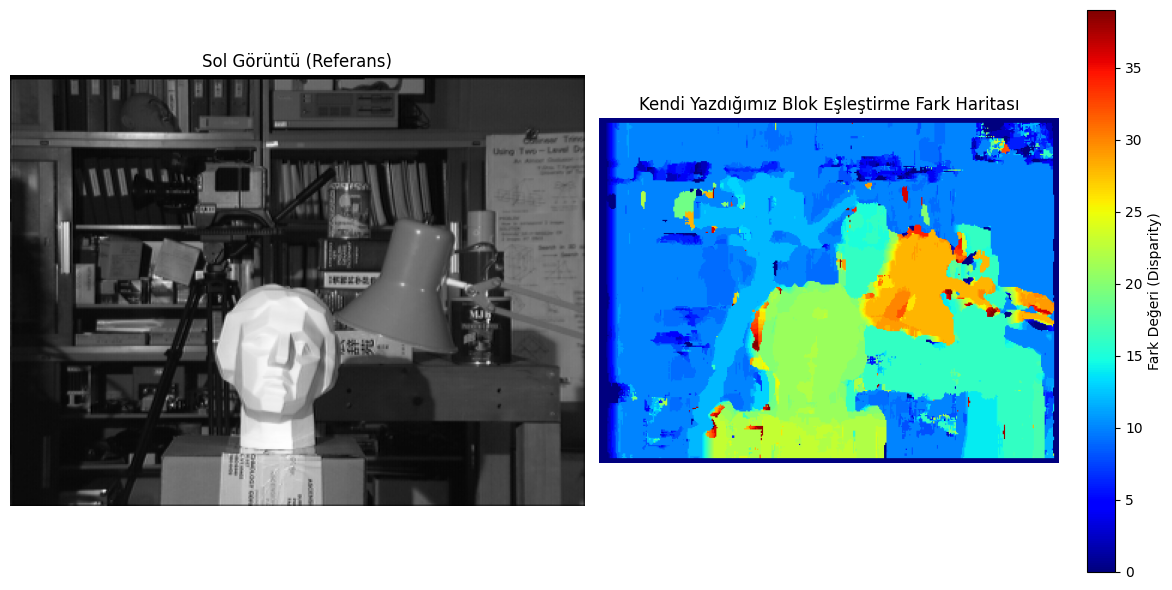

In [7]:
# Sonucu görselleştirelim
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.title("Sol Görüntü (Referans)")
plt.imshow(img_left, cmap='gray')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title("Kendi Yazdığımız Blok Eşleştirme Fark Haritası")
plt.imshow(custom_disparity, cmap='jet')
plt.colorbar(label='Fark Değeri (Disparity)')
plt.axis('off')

plt.tight_layout()
plt.show()